In [1]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt

In [2]:
train = (
    pd.read_csv('../Datasets/train.csv')
    .rename(columns={'market_forward_excess_returns': 'target'})
)

# Cast all columns except 'date_id' to float
cols_to_cast = [c for c in train.columns if c != 'date_id']
train[cols_to_cast] = train[cols_to_cast].astype(float)

## Feature DataFrame

In [3]:
feature_df = train.copy()

M_cols = [c for c in feature_df.columns if c.startswith('M')]
E_cols = [c for c in feature_df.columns if c.startswith('E')]
I_cols = [c for c in feature_df.columns if c.startswith('I')]
P_cols = [c for c in feature_df.columns if c.startswith('P')]
V_cols = [c for c in feature_df.columns if c.startswith('V')]
S_cols = [c for c in feature_df.columns if c.startswith('S')]
D_cols = [c for c in feature_df.columns if c.startswith('D')]

feature_df['lagged_risk_free_rate'] = feature_df['risk_free_rate'].shift(1)
feature_df['lagged_forward_returns'] = feature_df['forward_returns'].shift(1)
feature_df['lagged_target'] = feature_df['target'].shift(1)

baseline_features = (
    M_cols + E_cols + I_cols + P_cols + V_cols + S_cols + D_cols +
    ['lagged_risk_free_rate', 'lagged_forward_returns', 'lagged_target']
)

print('Number of baseline features:', len(baseline_features))

Number of baseline features: 97


## Engineered Features

In [4]:
M4 = feature_df['M4']
LFR = feature_df['lagged_forward_returns']
prod = M4 * LFR
feature_df['M4_LaggedF_MR'] = -np.sign(M4) * np.maximum(prod, 0.0)


J = feature_df['M4_LaggedF_MR']
P7 = feature_df['P7']
J_P7_opposite = (np.sign(J) * np.sign(P7) < 0).astype(float)
feature_df['J_P7_gated'] = J * J_P7_opposite


feature_df['M4_Reverse'] = -1 * feature_df['M4']


feature_df['P7_sell_flag'] = (
    (feature_df['P7'] > -1) & (feature_df['P7'] < 0)
).astype(int)


feature_df['M4_P7'] = feature_df['M4'] * feature_df['P7']


feature_df['P6_P7_spread'] = feature_df['P6'] - feature_df['P7']


E19_HIGH = feature_df['E19'].quantile(0.99)
feature_df['E19_clip'] = feature_df['E19'].clip(upper=E19_HIGH)
feature_df['E19_right_tail_flag'] = (feature_df['E19'] > E19_HIGH).astype(int)


P3_SMALL = feature_df['P3'].quantile(0.14)
feature_df['P3_small_flag'] = (feature_df['P3'] <= P3_SMALL).astype(int)


feature_df['E19_P3'] = feature_df['E19'] * feature_df['P3']


engineered_features = [
    'M4_LaggedF_MR', 'J_P7_gated', 
    'M4_Reverse', 'P7_sell_flag', 'M4_P7', 'P6_P7_spread',
    'E19_clip', 'E19_right_tail_flag', 'P3_small_flag', 'E19_P3'
]

In [5]:
# Final feature list
features = baseline_features + engineered_features
print('Total number of features:', len(features))

Total number of features: 107


## Depth=2 因子挖掘树模型的参数

In [6]:
PARAMS_INTERACTION_PROBE = {
    'max_depth': 2,
    'learning_rate': 0.03,
    'n_estimators': 1000,
    'colsample_bytree': 0.5,
    'subsample': 0.8,
    'reg_lambda': 10,          # 压一压叶子权重，抑制小样本的噪音 split
    'min_child_weight': 10,    # 限制极端小样本叶子
    'tree_method': 'hist',
    'random_state': 42,
    'n_jobs': -1,
}

## CV

In [7]:
DATES = feature_df['date_id'].unique()
START_DATE_ID = int(DATES[0])
print('Start date_id:', START_DATE_ID)
END_DATE_ID = int(DATES[-1])
print('End date_id:', END_DATE_ID)
N_DATES = END_DATE_ID - START_DATE_ID + 1
print('Total number of trading days in the feature DataFrame:', N_DATES)

# purge 为了避免构建上面 lag 特征的数据泄露问题
# 其实 purge=1 就足够了因为都是 shift(1)，并且不打算再加入其他时序特征
PURGE = 2
OUTER_TRAIN_SIZE = 252 * 5  # 5 years
OUTER_TEST_SIZE = 126  # 6 months
INNER_FOLDS = 5
INNER_TRAIN_SIZE = 252 * 3  # 3 year
INNER_VAL_SIZE = OUTER_TEST_SIZE  # 6 months
STEP = 93

Start date_id: 0
End date_id: 9020
Total number of trading days in the feature DataFrame: 9021


In [8]:
def get_day_forward_chaining_nested_cv(
    dates, purge, outer_train_size, outer_test_size, 
    inner_folds, inner_train_size, inner_val_size, step
):
    """
    Generates indices for Day Forward-Chaining Nested CV
    """
    
    start_date_id = int(dates[0])
    end_date_id = int(dates[-1])
    n_dates = end_date_id - start_date_id + 1

    # OUTER LOOP
    outer_folds_count = ((n_dates - outer_train_size - purge - outer_test_size) // outer_test_size) + 1
    
    for outer_i in range(outer_folds_count):
        outer_train_start = start_date_id + outer_i * outer_test_size
        outer_train_end = outer_train_start + outer_train_size - 1
        outer_test_start = outer_train_end + purge + 1

        # adjust last outer fold to hit last date_id exactly
        if outer_i == outer_folds_count - 1:
            outer_test_end = end_date_id
        else:
            outer_test_end = outer_test_start + outer_test_size - 1

        outer_train_idx = (outer_train_start, outer_train_end)
        outer_test_idx = (outer_test_start, outer_test_end)
        
        # INNER SPLITS
        inner_splits = []

        for inner_i in range(inner_folds):
            inner_train_start = outer_train_start + inner_i * step
            inner_train_end = inner_train_start + inner_train_size - 1
            inner_val_start = inner_train_end + purge + 1
            inner_val_end = inner_val_start + inner_val_size - 1

            # Adjust last inner fold to hit outer_train_end exactly
            if inner_i == inner_folds - 1:
                inner_val_end = outer_train_end
                inner_val_start = inner_val_end - inner_val_size + 1
                inner_train_end = inner_val_start - purge - 1
                inner_train_start = inner_train_end - inner_train_size + 1

            inner_train_idx = (int(inner_train_start), int(inner_train_end))
            inner_val_idx = (int(inner_val_start), int(inner_val_end))
            inner_splits.append((inner_train_idx, inner_val_idx))
            
        yield outer_train_idx, outer_test_idx, inner_splits

In [9]:
# Initialize the generator
cv_generator = get_day_forward_chaining_nested_cv(
    dates=DATES,
    purge=PURGE,
    outer_train_size=OUTER_TRAIN_SIZE,
    outer_test_size=OUTER_TEST_SIZE,
    inner_folds=INNER_FOLDS,
    inner_train_size=INNER_TRAIN_SIZE,
    inner_val_size=INNER_VAL_SIZE,
    step=STEP
)

In [10]:
from scoring_metric import score, ParticipantVisibleError
print('Competition metric imported successfully!')

Competition metric imported successfully!


In [11]:
def run_day_forward_chaining_nested_cv(
    feature_df, features, cv_generator, model, params, 
    signal_multiplier=90, verbose=True
):

    inner_scores_dict = {}
    inner_models_dict = {}
    inner_val_data_dict = {}
    mean_inner_scores_list = []
    preds_dict = {}

    for outer_i, (outer_train_idx, outer_test_idx, inner_splits) in enumerate(cv_generator, start=1):
        if verbose:
            print(f"\n===== OUTER FOLD {outer_i} =====")

        # Build outer fold masks
        outer_train_mask = feature_df['date_id'].between(outer_train_idx[0], outer_train_idx[1])
        outer_test_mask = feature_df['date_id'].between(outer_test_idx[0], outer_test_idx[1])

        X_train_outer = feature_df.loc[outer_train_mask, features]
        y_train_outer = feature_df.loc[outer_train_mask, 'target']
        X_test_outer = feature_df.loc[outer_test_mask,  features]
        solution_outer = feature_df.loc[outer_test_mask, ['forward_returns', 'risk_free_rate']].copy()

        # Create storage for this outer fold
        inner_models_dict[outer_i] = []
        inner_val_data_dict[outer_i] = []
        inner_scores_dict[outer_i] = []
        preds_dict[outer_i] = []

        # INNER FOLD LOOP
        for inner_j, (inner_train_idx, inner_val_idx) in enumerate(inner_splits, start=1):

            # Build inner masks
            inner_train_mask = feature_df['date_id'].between(inner_train_idx[0], inner_train_idx[1])
            inner_val_mask = feature_df['date_id'].between(inner_val_idx[0], inner_val_idx[1])

            assert inner_train_idx[1] < inner_val_idx[0], "Leakage: inner train/val overlapping!"

            X_train_inner = feature_df.loc[inner_train_mask, features]
            y_train_inner = feature_df.loc[inner_train_mask, 'target']
            X_val_inner = feature_df.loc[inner_val_mask, features]
            y_val_inner = feature_df.loc[inner_val_mask, 'target']  # this is not explicitly used
            
            solution_inner = feature_df.loc[inner_val_mask, ['forward_returns', 'risk_free_rate']].copy()

            assert X_train_inner.shape == (756, len(features)), "Inner train shape incorrect"
            assert X_val_inner.shape == (126, len(features)), "Inner validation shape incorrect"

            # Train inner model
            model_inner = model(**params)
            model_inner.fit(X_train_inner, y_train_inner)

            # Store the inner model and validation data
            inner_models_dict[outer_i].append(model_inner)

            inner_val_data_dict[outer_i].append({
                "X_val": X_val_inner.copy(),
                "y_val": y_val_inner.copy(),
                "solution": solution_inner.copy()
            })

            # Score inner fold
            preds_inner = model_inner.predict(X_val_inner)
            preds_dict[outer_i].append(preds_inner)
            position_inner = np.clip(preds_inner * signal_multiplier + 1, 0, 2)
            submission_inner = pd.DataFrame({'prediction': position_inner}, index=X_val_inner.index)

            score_inner = score(solution_inner, submission_inner, 'index')
            inner_scores_dict[outer_i].append(score_inner)

        # Mean Sharpe of this outer fold
        mean_score = np.mean(inner_scores_dict[outer_i])
        mean_inner_scores_list.append(mean_score)
        
        if verbose:
            print(f"\nMean Inner Sharpe (Outer Fold {outer_i}): "
                  f"{mean_score:.6f}")

        # OUTER MODEL
        # DO NOT USE IT AT FEATURE ENGINEERING STAGE; FOR FINAL EVALUATION ONLY
        model_outer = model(**params)
        model_outer.fit(X_train_outer, y_train_outer)

        preds_outer = model_outer.predict(X_test_outer)
        position_outer = np.clip(preds_outer * signal_multiplier + 1, 0, 2)
        submission_outer = pd.DataFrame({'prediction': position_outer}, index=X_test_outer.index)

        # Compute outer score but do NOT store it
        _ = score(solution_outer, submission_outer, 'index')

    overall_mean_score = np.mean(mean_inner_scores_list)
    print("\n" + "="*30)
    print(f"OVERALL MEAN CV SCORE: {overall_mean_score:.6f}")
    print("="*30)

    # Return everything needed for SHAP analysis later
    return {
        'inner_scores_dict': inner_scores_dict,
        'inner_models_dict': inner_models_dict,
        'inner_val_data_dict': inner_val_data_dict,
        'preds_dict': preds_dict
    }

In [12]:
results = run_day_forward_chaining_nested_cv(
    feature_df, features, cv_generator, xgb.XGBRegressor, PARAMS_INTERACTION_PROBE
)


===== OUTER FOLD 1 =====

Mean Inner Sharpe (Outer Fold 1): 0.571380

===== OUTER FOLD 2 =====

Mean Inner Sharpe (Outer Fold 2): 0.755960

===== OUTER FOLD 3 =====

Mean Inner Sharpe (Outer Fold 3): 1.459602

===== OUTER FOLD 4 =====

Mean Inner Sharpe (Outer Fold 4): 2.040694

===== OUTER FOLD 5 =====

Mean Inner Sharpe (Outer Fold 5): 1.933034

===== OUTER FOLD 6 =====

Mean Inner Sharpe (Outer Fold 6): 1.978239

===== OUTER FOLD 7 =====

Mean Inner Sharpe (Outer Fold 7): 1.712411

===== OUTER FOLD 8 =====

Mean Inner Sharpe (Outer Fold 8): 2.128344

===== OUTER FOLD 9 =====

Mean Inner Sharpe (Outer Fold 9): 1.569164

===== OUTER FOLD 10 =====

Mean Inner Sharpe (Outer Fold 10): 1.646601

===== OUTER FOLD 11 =====

Mean Inner Sharpe (Outer Fold 11): 1.194052

===== OUTER FOLD 12 =====

Mean Inner Sharpe (Outer Fold 12): 1.285295

===== OUTER FOLD 13 =====

Mean Inner Sharpe (Outer Fold 13): 1.162696

===== OUTER FOLD 14 =====

Mean Inner Sharpe (Outer Fold 14): 0.648647

===== OUT

In [13]:
def evaluate_multiplier(results, multiplier):
    all_scores = []

    for outer_i in results['preds_dict']:
        for inner_j, preds_inner in enumerate(results['preds_dict'][outer_i]):
            solution = results['inner_val_data_dict'][outer_i][inner_j]['solution']
            position = np.clip(preds_inner * multiplier + 1, 0, 2)
            submission = pd.DataFrame({'prediction': position}, index=solution.index)
            score_inner = score(solution, submission, 'index')
            all_scores.append(score_inner)
    
    return np.mean(all_scores)

In [14]:
multipliers = np.linspace(0, 200, 81)  # 0, 5, 10, ..., 200
sharpe_results = {}

for m in multipliers:
    sharpe = evaluate_multiplier(results, m)
    sharpe_results[m] = sharpe

In [15]:
best_multiplier = max(sharpe_results, key=sharpe_results.get)
print("\nBest Multiplier:", best_multiplier)
print("Best Sharpe:", sharpe_results[best_multiplier])


Best Multiplier: 127.5
Best Sharpe: 1.081757835634492


## SAVE

In [16]:
def find_interaction_pairs_from_trees(
    model,
    use_pair_gain: bool = True,
    verbose: bool = False,
) -> pd.DataFrame:

    """
    Mine symmetric feature interaction pairs from an XGBoost model using tree structure.

    Treats (A, B) and (B, A) as the same pair.
    Returns columns: Feature_A, Feature_B, Frequency, Total_Gain, Mean_Gain.
    """

    trees = model.get_booster().trees_to_dataframe()
    splits = trees[trees['Feature'] != 'Leaf'].copy()

    children = splits[['Tree', 'ID', 'Feature', 'Gain']].rename(
        columns={
            'ID': 'Child_ID',
            'Feature': 'Child_Feature',
            'Gain': 'Child_Gain'
        }
    )

    def merge_branch(branch_col: str):
        return pd.merge(
            splits[['Tree', 'ID', branch_col, 'Feature', 'Gain']],
            children,
            left_on=['Tree', branch_col],
            right_on=['Tree', 'Child_ID'],
            how='inner'
        )

    merged_yes = merge_branch('Yes')
    merged_no = merge_branch('No')
    interactions = pd.concat([merged_yes, merged_no], axis=0, ignore_index=True)

    interactions = interactions[interactions['Feature'] != interactions['Child_Feature']]

    if use_pair_gain:
        interactions['Interaction_Gain'] = interactions['Gain'] + interactions['Child_Gain']
    else:
        interactions['Interaction_Gain'] = interactions['Child_Gain']

    pair_sorted = np.sort(
        interactions[['Feature', 'Child_Feature']].values,
        axis=1
    )
    interactions['Feature_A'] = pair_sorted[:, 0]
    interactions['Feature_B'] = pair_sorted[:, 1]

    summary = (
        interactions
        .groupby(['Feature_A', 'Feature_B'])['Interaction_Gain']
        .agg(['count', 'sum'])
        .reset_index()
    )
    summary.columns = ['Feature_A', 'Feature_B', 'Frequency', 'Total_Gain']

    summary['Mean_Gain'] = summary['Total_Gain'] / summary['Frequency']

    summary = summary.sort_values(
        ['Total_Gain', 'Mean_Gain'],
        ascending=[False, False]
    ).reset_index(drop=True)

    if verbose:
        print(f'Found {len(summary)} symmetric interacting pairs in tree structure.')
        print('Top 5 Interactions by Gain:\n')
        print(summary.head(5))
        print()

    return summary

In [17]:
def aggregate_interaction_pairs_across_folds(
    results,
    verbose: bool = True,
) -> pd.DataFrame:

    """
    Aggregate symmetric interaction pairs across all models.
    """

    all_pairs = []

    # use ALL outer folds
    outer_keys = sorted(results['inner_models_dict'].keys())

    for outer in outer_keys:
        inner_models = results['inner_models_dict'][outer]

        for inner_j, model_inner in enumerate(inner_models, start=1):
            pairs = find_interaction_pairs_from_trees(
                model_inner,
                use_pair_gain=True,
                verbose=False
            ).copy()

            pairs['outer_fold'] = outer
            pairs['inner_fold'] = inner_j
            all_pairs.append(pairs)

    # Stack all models together
    interactions_df = pd.concat(all_pairs, ignore_index=True)

    # Aggregate globally by symmetric pair
    global_pairs = (
        interactions_df
        .groupby(['Feature_A', 'Feature_B'])
        .agg(
            Models_Count=('Total_Gain', 'size'),   # in how many models this pair appeared
            Total_Gain=('Total_Gain', 'sum'),      # sum of Total_Gain across models
            Sum_Frequency=('Frequency', 'sum'),    # total # of edges across models
            Mean_Frequency=('Frequency', 'mean'),  # avg freq per model (conditional on appearing)
        )
        .reset_index()
    )

    global_pairs['Avg_Gain_per_Split'] = (
        global_pairs['Total_Gain'] / global_pairs['Sum_Frequency']
    )

    global_pairs = global_pairs.sort_values(
        ['Total_Gain', 'Avg_Gain_per_Split'],
        ascending=[False, False]
    ).reset_index(drop=True)

    print('Top 20 Pairs Across All Folds:\n')
    print(global_pairs.head(20))

    return global_pairs

In [18]:
global_pairs = aggregate_interaction_pairs_across_folds(results)

Top 20 Pairs Across All Folds:

        Feature_A               Feature_B  Models_Count  Total_Gain  \
0             E16                     P10            86    1.383741   
1          E19_P3                     P10           184    0.953252   
2              I2                      V9            58    0.903934   
3          E19_P3                      P3           183    0.884163   
4          E19_P3  lagged_forward_returns           177    0.866653   
5             E16                     V13            74    0.840316   
6             E16                     P11            78    0.835979   
7              P5  lagged_forward_returns           139    0.831738   
8   M4_LaggedF_MR                      P7           157    0.820887   
9              P6                      S2           181    0.814876   
10             P4                      P6           153    0.812545   
11             I2                     P10           117    0.757172   
12            P12  lagged_forward_returns    

## SHAP

In [19]:
import shap

all_mean_abs = []
all_mean_signed = []

# Loop over each outer fold
for outer_fold in results['inner_models_dict'].keys():

    models = results['inner_models_dict'][outer_fold]  
    val_sets = results['inner_val_data_dict'][outer_fold]
    
    for model_inner, val_data in zip(models, val_sets):
        
        X_val_inner = val_data['X_val']
        
        explainer = shap.TreeExplainer(model_inner)
        shap_values = explainer.shap_values(X_val_inner)
        
        # mean absolute SHAP values (magnitude)
        all_mean_abs.append(np.abs(shap_values).mean(axis=0))
        
        # mean signed SHAP values (direction)
        all_mean_signed.append(shap_values.mean(axis=0))

# Convert from list to arrays
all_mean_abs_arr = np.array(all_mean_abs)
all_mean_signed_arr = np.array(all_mean_signed)

print('Shape of all_mean_abs:', all_mean_abs_arr.shape)
print('Shape of all_mean_signed:', all_mean_signed_arr.shape)

Shape of all_mean_abs: (305, 107)
Shape of all_mean_signed: (305, 107)


In [20]:
# Final aggregated SHAP
mean_abs_shap = np.mean(all_mean_abs_arr, axis=0)
print('Shape of mean_abs_shap:', mean_abs_shap.shape)

mean_signed_shap = np.mean(all_mean_signed_arr, axis=0)
print('Shape of mean_signed_shap:', mean_signed_shap.shape)

# Create DataFrame
direction_df = pd.DataFrame({
    'feature': features,
    'mean_abs_shap': mean_abs_shap,
    'mean_signed_shap': mean_signed_shap
})

direction_df['direction'] = np.where(
    direction_df['mean_signed_shap'] > 0, 'Positive', 'Negative'
)

direction_df = direction_df.sort_values('mean_abs_shap', ascending=False)

Shape of mean_abs_shap: (107,)
Shape of mean_signed_shap: (107,)


In [21]:
direction_df

,feature,mean_abs_shap,mean_signed_shap,direction
17,M9,6.067457e-04,-2.728727e-05,Negative
48,P10,5.610829e-04,1.824926e-04,Positive
64,V13,5.118834e-04,1.145069e-04,Positive
51,P13,4.675060e-04,3.650166e-05,Positive
70,V7,4.347901e-04,1.476342e-04,Positive
...,...,...,...,...
87,D3,1.604999e-05,2.181326e-08,Positive
88,D4,1.394590e-05,2.537835e-08,Positive
105,P3_small_flag,1.255959e-05,-3.019555e-09,Negative
86,D2,9.283522e-06,5.640723e-08,Positive


In [22]:
top_features = direction_df.head(50)['feature'].tolist()
print('Top 50 Features:')
print(top_features)
bottom_features = direction_df.tail(57)['feature'].tolist()
print('\nBottom 57 Features:')
print(bottom_features)

Top 50 Features:
['M9', 'P10', 'V13', 'P13', 'V7', 'E19_P3', 'M11', 'E3', 'E2', 'M4', 'S5', 'P4', 'V3', 'P11', 'P6', 'S2', 'P3', 'M4_Reverse', 'P2', 'P7', 'P5', 'M3', 'V5', 'P6_P7_spread', 'P12', 'S6', 'P8', 'I8', 'E19', 'I4', 'M4_LaggedF_MR', 'I1', 'I7', 'M10', 'lagged_forward_returns', 'I6', 'M4_P7', 'M12', 'I2', 'I5', 'E8', 'I3', 'M7', 'E20', 'V2', 'M18', 'M8', 'P9', 'I9', 'E4']

Bottom 57 Features:
['M15', 'P1', 'E16', 'E5', 'lagged_risk_free_rate', 'S7', 'S11', 'E19_clip', 'M1', 'S9', 'lagged_target', 'S10', 'S12', 'E11', 'E13', 'E15', 'V4', 'E12', 'E18', 'M17', 'M2', 'E14', 'E17', 'S4', 'V9', 'S8', 'J_P7_gated', 'E10', 'E6', 'S1', 'V6', 'E1', 'M6', 'E9', 'M5', 'M14', 'S3', 'P7_sell_flag', 'V1', 'V12', 'V10', 'D7', 'V8', 'M16', 'M13', 'D6', 'D8', 'V11', 'E7', 'D5', 'D9', 'D1', 'D3', 'D4', 'P3_small_flag', 'D2', 'E19_right_tail_flag']


## SHAP Dependence Plots
画 SHAP Dependence Plots，用来观察排名靠前的特征对，理解它们是如何交互的

In [23]:
def compute_shap_interaction(results, target_feature, last_n_outer=None):

    # outer fold 的 key，比如 1-61
    all_outer_keys = list(results['inner_models_dict'].keys())
    # 为了稳一点，可以排序一下（1,2,...,61）
    all_outer_keys = sorted(all_outer_keys)

    if last_n_outer is None:
        selected_outers = all_outer_keys
    else:
        selected_outers = all_outer_keys[-last_n_outer:]

    print('Outer Folds:', selected_outers)
    print('\n')

    interaction_list = []

    for outer in selected_outers:
        models = results['inner_models_dict'][outer]
        val_sets = results['inner_val_data_dict'][outer]

        # 每个 inner fold 都做一次 interaction SHAP
        for model, val_data in zip(models, val_sets):
            X_val = val_data['X_val']
            n_samples, n_features = X_val.shape  # (126, 特征总数）

            explainer = shap.TreeExplainer(model)
            shap_interaction_values = explainer.shap_interaction_values(X_val)
            # (样本数，特征数，特征数）代表第 i 个样本中，第 j 个特征与第 k 个特征的交互 SHAP 值
            assert shap_interaction_values.shape == (n_samples, n_features, n_features)

            target_feature_index = list(X_val.columns).index(target_feature)
            # 取绝对值，因为我们只关心交互“强度”（不分方向）
            interaction_strength = np.abs(
                shap_interaction_values[:, target_feature_index, :]
            ).mean(0)
            assert interaction_strength.shape == (n_features,)

            interaction_list.append(interaction_strength)

    if len(interaction_list) == 0:
        raise ValueError("interaction_list is empty — 检查一下 last_n_outer 是否选到了任何 folds。")

    # 把所有 (outer, inner) 的 interaction_strength 堆叠，再取平均
    final_interaction = np.mean(np.vstack(interaction_list), axis=0)

    interaction_df = pd.DataFrame({
        'features': X_val.columns,
        'interaction_strength': final_interaction
    }).sort_values('interaction_strength', ascending=False)

    print(
        'Top 10 features interacting with {} (from {} outer folds):\n'.format(
            target_feature,
            len(selected_outers)
        )
    )
    print(interaction_df[interaction_df['features'] != target_feature].head(10))

    return interaction_df

In [24]:
def plot_shap_interaction(results, feature_A, feature_B, last_n_outer=None):

    """
    Aggregate SHAP values across selected outer folds and
    plot a SHAP dependence plot for (feature_A, feature_B).

    If last_n_outer is None: use all outer folds.
    If last_n_outer is an int: only use the last N outer folds.
    """

    all_outer_keys = sorted(results['inner_models_dict'].keys())

    if last_n_outer is not None:
        all_outer_keys = all_outer_keys[-last_n_outer:]

    all_shap = []
    all_X_val = []

    for outer in all_outer_keys:
        models = results['inner_models_dict'][outer]
        val_sets = results['inner_val_data_dict'][outer]

        for model, val_data in zip(models, val_sets):
            X_val = val_data['X_val']
            n_samples, n_features = X_val.shape

            explainer = shap.TreeExplainer(model)
            shap_values = explainer.shap_values(X_val)
            assert shap_values.shape == (n_samples, n_features)

            all_shap.append(shap_values)
            all_X_val.append(X_val)

    all_shap = np.vstack(all_shap)
    all_X_val = pd.concat(all_X_val, axis=0)

    print('Shape of all_shap:', all_shap.shape)
    print('Shape of all_X_val:', all_X_val.shape)

    plt.figure(figsize=(10, 6))
    shap.dependence_plot(
        feature_A,
        all_shap,
        all_X_val,
        interaction_index=feature_B,
        alpha=0.4,   # 可以再调低一点
        show=False
    )

    title_suffix = (
        f"Last {last_n_outer} outer folds" if last_n_outer is not None
        else "All Folds"
    )
    plt.title(f"{title_suffix}: How {feature_A} interacts with {feature_B}")
    plt.grid(True, alpha=0.3)
    plt.show()

    return all_shap, all_X_val

In [25]:
x = compute_shap_interaction(results, target_feature='M4_LaggedF_MR', last_n_outer=None)

Outer Folds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61]


Top 10 features interacting with M4_LaggedF_MR (from 61 outer folds):

                   features  interaction_strength
57                       P7              0.000007
95   lagged_forward_returns              0.000006
53                       P3              0.000005
96            lagged_target              0.000004
100              M4_Reverse              0.000004
12                       M4              0.000004
77                       S2              0.000004
54                       P4              0.000003
103            P6_P7_spread              0.000003
80                       S5              0.000003


In [28]:
M4_interaction_df = compute_shap_interaction(results, target_feature='M4', last_n_outer=None)

Outer Folds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61]


Top 10 features interacting with M4 (from 61 outer folds):

                   features  interaction_strength
95   lagged_forward_returns              0.000007
56                       P6              0.000007
54                       P4              0.000007
80                       S5              0.000007
57                       P7              0.000007
53                       P3              0.000006
17                       M9              0.000006
103                  E19_P3              0.000006
40                       I3              0.000005
11                       M3              0.000005


### M4 和 lagged_forward_returns

Shape of all_shap: (38430, 105)
Shape of all_X_val: (38430, 105)


<Figure size 1000x600 with 0 Axes>

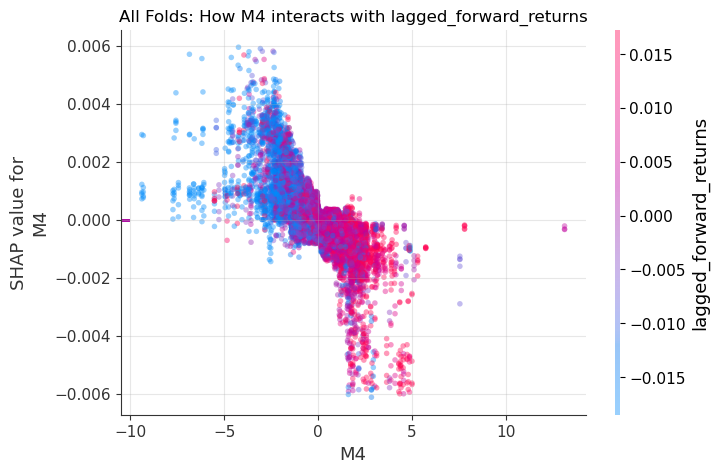

In [25]:
M4_LaggedF_all_shap, M4_LaggedF_all_X_val = plot_shap_interaction(
    results, feature_A='M4', feature_B='lagged_forward_returns', last_n_outer=None
)

Shape of all_shap: (38430, 105)
Shape of all_X_val: (38430, 105)


<Figure size 1000x600 with 0 Axes>

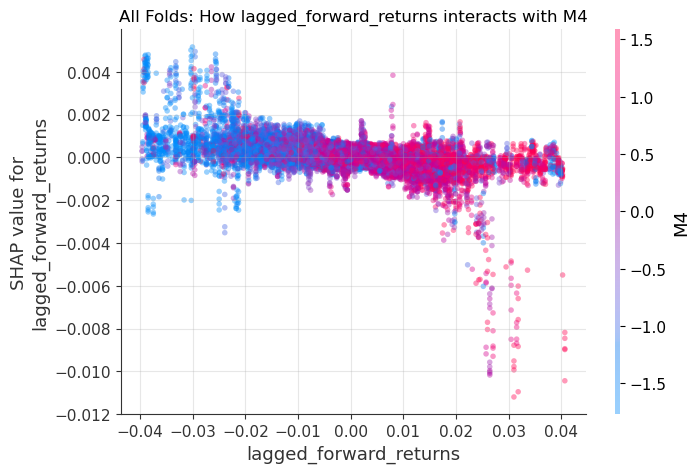

In [26]:
LaggedF_M4_all_shap, LaggedF_M4_all_X_val = plot_shap_interaction(
    results, feature_A='lagged_forward_returns', feature_B='M4', last_n_outer=None
)

### M4_LaggedF_MR 和 P7

Shape of all_shap: (38430, 107)
Shape of all_X_val: (38430, 107)


<Figure size 1000x600 with 0 Axes>

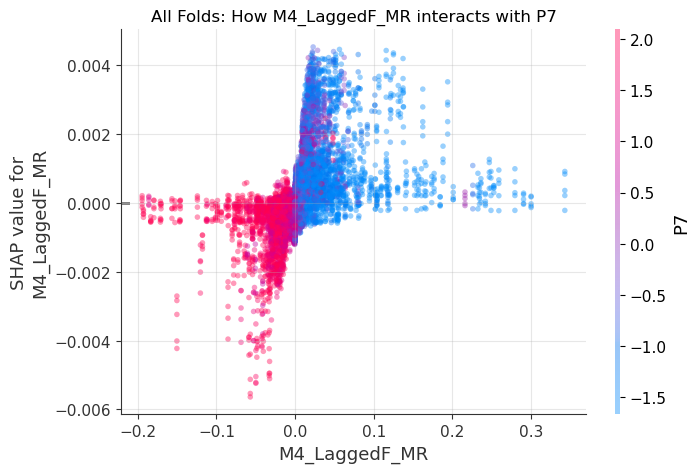

In [25]:
M4_LaggedF_MR_P7_all_shap, M4_LaggedF_MR_P7_all_X_val = plot_shap_interaction(
    results, feature_A='M4_LaggedF_MR', feature_B='P7', last_n_outer=None
)

Shape of all_shap: (38430, 106)
Shape of all_X_val: (38430, 106)


<Figure size 1000x600 with 0 Axes>

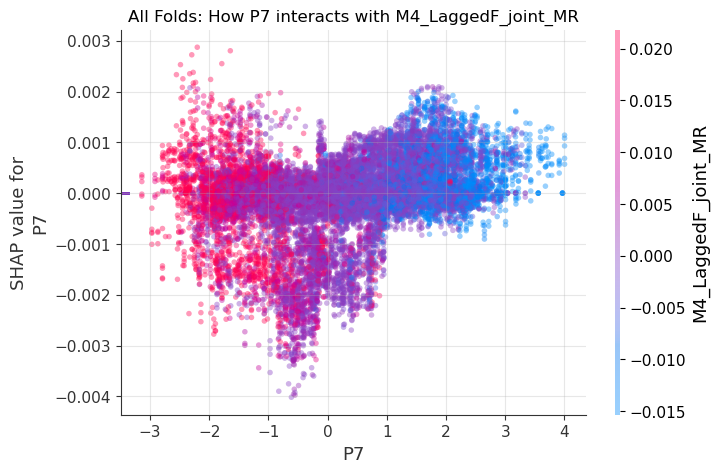

In [27]:
P7_M4_LaggedF_MR_all_shap, M4_LaggedF_MR_P7_all_X_val = plot_shap_interaction(
    results, feature_A='P7', feature_B='M4_LaggedF_joint_MR', last_n_outer=None
)

### E16 和 P10

Shape of all_shap: (38430, 108)
Shape of all_X_val: (38430, 108)


<Figure size 1000x600 with 0 Axes>

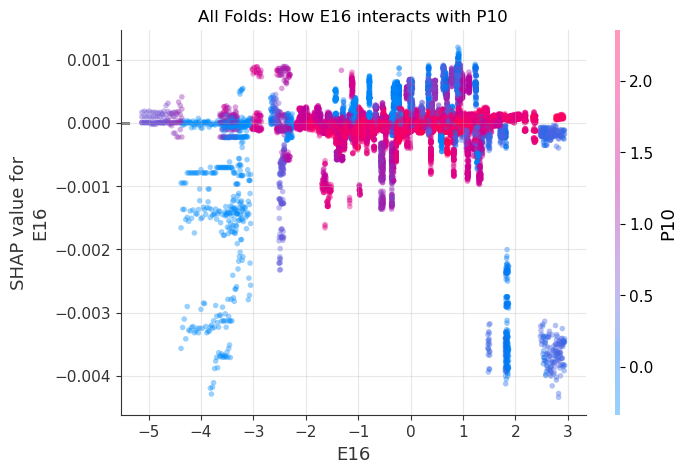

In [34]:
E16_P10_all_shap, E16_P10_all_X_val = plot_shap_interaction(
    results, feature_A='E16', feature_B='P10', last_n_outer=None
)

Shape of all_shap: (38430, 108)
Shape of all_X_val: (38430, 108)


<Figure size 1000x600 with 0 Axes>

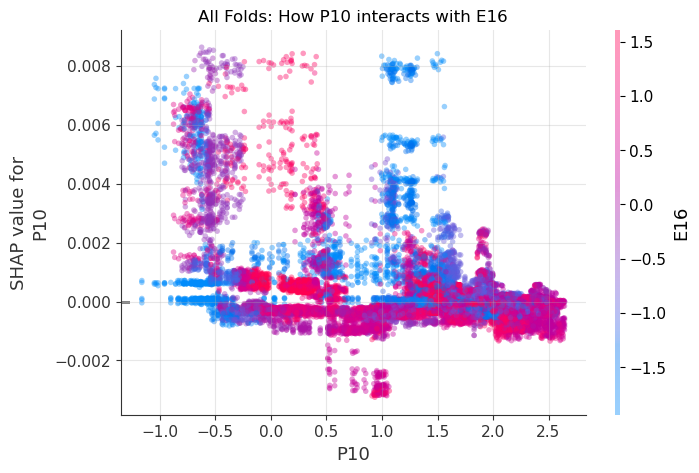

In [35]:
P10_E16_all_shap, P10_E16_all_X_val = plot_shap_interaction(
    results, feature_A='P10', feature_B='E16', last_n_outer=None
)

### M4 和 P7

Shape of all_shap: (38430, 98)
Shape of all_X_val: (38430, 98)


<Figure size 1000x600 with 0 Axes>

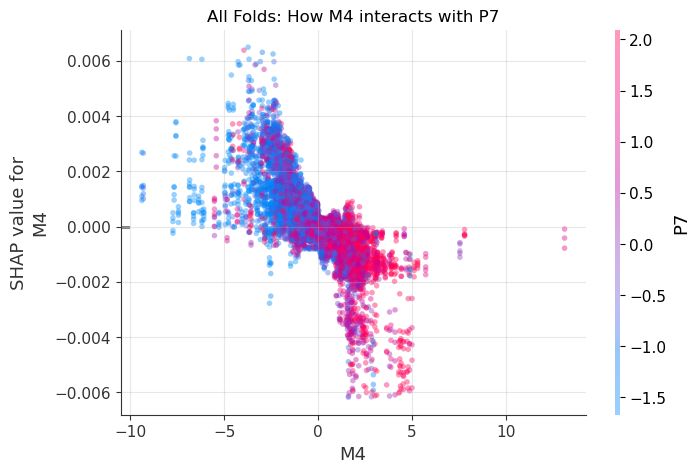

In [35]:
M4_P7_all_shap, M4_P7_all_X_val = plot_shap_interaction(
    results, feature_A='M4', feature_B='P7', last_n_outer=None
)

Shape of all_shap: (38430, 104)
Shape of all_X_val: (38430, 104)


<Figure size 1000x600 with 0 Axes>

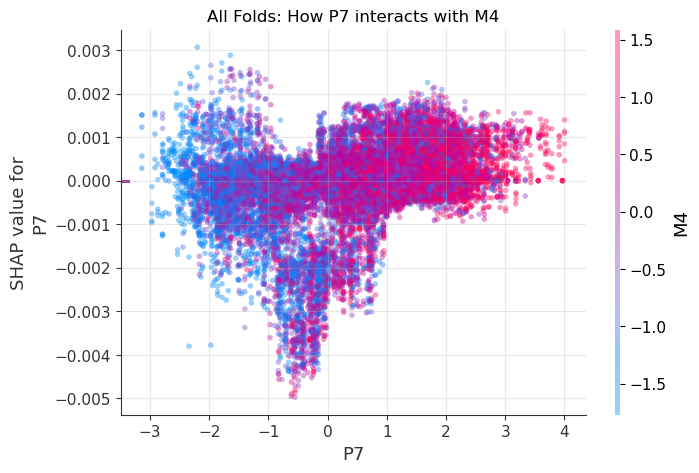

In [33]:
P7_M4_all_shap, P7_M4_all_X_val = plot_shap_interaction(
    results, feature_A='P7', feature_B='M4', last_n_outer=None
)

### M4 和 P6

Shape of all_shap: (38430, 104)
Shape of all_X_val: (38430, 104)


<Figure size 1000x600 with 0 Axes>

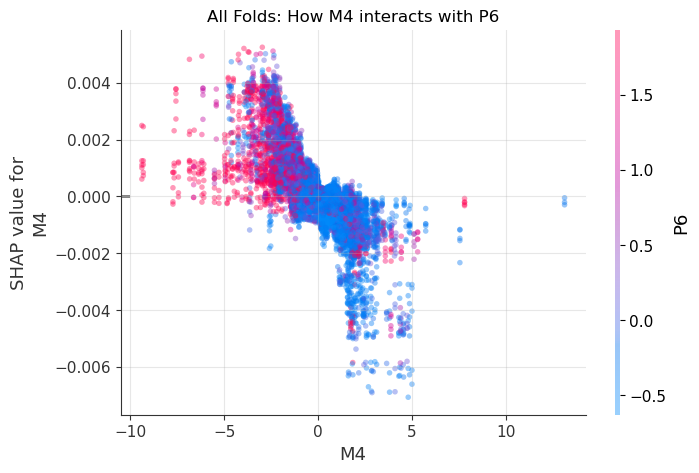

In [25]:
M4_P6_all_shap, M4_P6_all_X_val = plot_shap_interaction(
    results, feature_A='M4', feature_B='P6', last_n_outer=None
)

Shape of all_shap: (38430, 104)
Shape of all_X_val: (38430, 104)


<Figure size 1000x600 with 0 Axes>

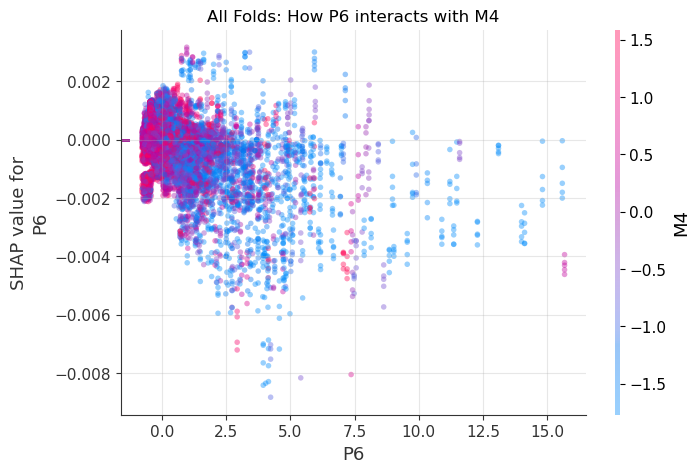

In [26]:
P6_M4_all_shap, P6_M4_all_X_val = plot_shap_interaction(
    results, feature_A='P6', feature_B='M4', last_n_outer=None
)

### E19 和 P3

Shape of all_shap: (38430, 98)
Shape of all_X_val: (38430, 98)


<Figure size 1000x600 with 0 Axes>

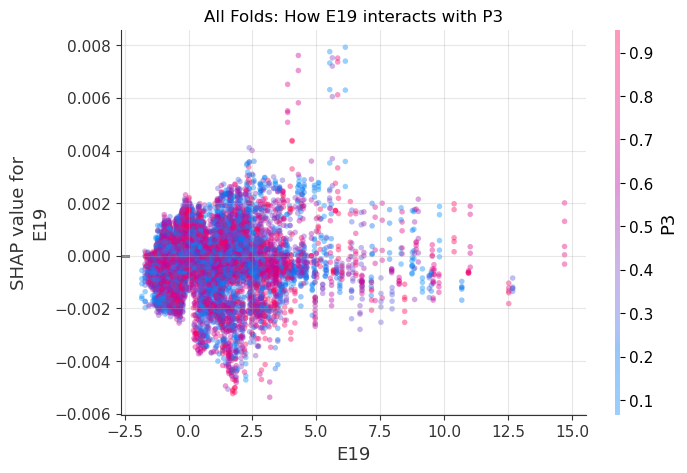

In [37]:
E19_P3_all_shap, E19_P3_all_X_val = plot_shap_interaction(
    results, feature_A='E19', feature_B='P3', last_n_outer=None
)

Shape of all_shap: (38430, 98)
Shape of all_X_val: (38430, 98)


<Figure size 1000x600 with 0 Axes>

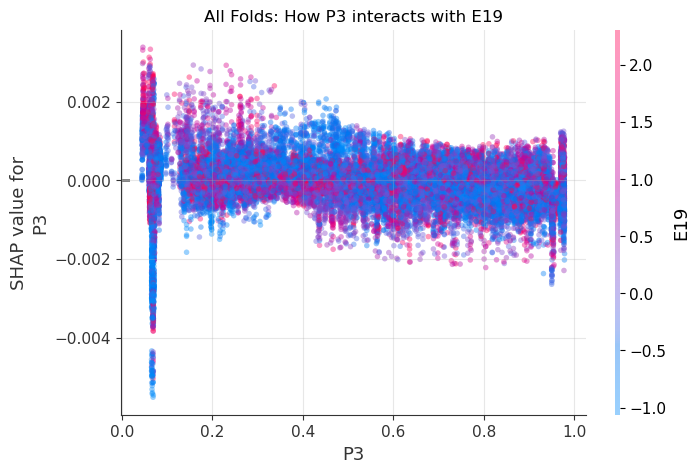

In [39]:
P3_E19_all_shap, P3_E19_all_X_val = plot_shap_interaction(
    results, feature_A='P3', feature_B='E19', last_n_outer=None
)